# Exploration du dataset complet (2014 → 2026)

Données : `data/processed_data/*.csv`, chargées avec `dataset_create.charger()` (voir `data/processed_data/README.md`).

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

from dataset_create import charger

df = charger()

AXES = ["Champs-Elysees", "Convention", "Saints-Peres"]
COULEURS = {"Champs-Elysees": "#2a78d6", "Convention": "#eb6834", "Saints-Peres": "#1baf7a"}
print(df.shape)
df.head()

(337464, 11)


,axe,arc_id,datetime_utc,debit,occupation,etat_trafic,etat_arc_code,ligne_absente,source,etat_arc,datetime
0,Champs-Elysees,4264,2014-01-01 00:00:00+00:00,4.0,0.00000,Fluide,3.0,False,old_data,NaN,2014-01-01 01:00:00+01:00
1,Champs-Elysees,4264,2014-01-01 01:00:00+00:00,21.0,0.10445,Fluide,3.0,False,old_data,NaN,2014-01-01 02:00:00+01:00
2,Champs-Elysees,4264,2014-01-01 02:00:00+00:00,417.0,6.12667,Fluide,3.0,False,old_data,NaN,2014-01-01 03:00:00+01:00
3,Champs-Elysees,4264,2014-01-01 03:00:00+00:00,1089.0,14.39890,Fluide,3.0,False,old_data,NaN,2014-01-01 04:00:00+01:00
4,Champs-Elysees,4264,2014-01-01 04:00:00+00:00,943.0,10.35220,Fluide,3.0,False,old_data,NaN,2014-01-01 05:00:00+01:00


In [3]:
meteo = pd.read_csv("data/external/meteo_paris.csv", parse_dates=["datetime_utc"])
df = df.merge(meteo, on="datetime_utc", how="left")
df

,axe,arc_id,datetime_utc,debit,occupation,etat_trafic,etat_arc_code,ligne_absente,source,etat_arc,datetime,temperature_2m,relative_humidity_2m,precipitation,snowfall,cloud_cover,wind_speed_10m,weather_code
0,Champs-Elysees,4264,2014-01-01 00:00:00+00:00,4.0,0.00000,Fluide,3.0,False,old_data,NaN,2014-01-01 01:00:00+01:00,5.9,91,0.0,0.0,10,17.0,0
1,Champs-Elysees,4264,2014-01-01 01:00:00+00:00,21.0,0.10445,Fluide,3.0,False,old_data,NaN,2014-01-01 02:00:00+01:00,5.5,93,0.0,0.0,5,16.3,0
2,Champs-Elysees,4264,2014-01-01 02:00:00+00:00,417.0,6.12667,Fluide,3.0,False,old_data,NaN,2014-01-01 03:00:00+01:00,5.2,93,0.0,0.0,8,17.1,0
3,Champs-Elysees,4264,2014-01-01 03:00:00+00:00,1089.0,14.39890,Fluide,3.0,False,old_data,NaN,2014-01-01 04:00:00+01:00,5.0,94,0.0,0.0,3,16.8,0
4,Champs-Elysees,4264,2014-01-01 04:00:00+00:00,943.0,10.35220,Fluide,3.0,False,old_data,NaN,2014-01-01 05:00:00+01:00,4.9,94,0.0,0.0,13,16.4,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
337459,Saints-Peres,191,2026-10-31 19:00:00+00:00,463.0,6.04056,Fluide,NaN,False,recent,Ouvert,2026-10-31 20:00:00+01:00,10.2,79,0.0,0.0,0,7.6,0
337460,Saints-Peres,191,2026-10-31 20:00:00+00:00,492.0,6.05778,Fluide,NaN,False,recent,Ouvert,2026-10-31 21:00:00+01:00,9.6,82,0.0,0.0,0,7.3,0
337461,Saints-Peres,191,2026-10-31 21:00:00+00:00,439.0,5.36889,Fluide,NaN,False,recent,Ouvert,2026-10-31 22:00:00+01:00,9.0,86,0.0,0.0,0,7.1,0
337462,Saints-Peres,191,2026-10-31 22:00:00+00:00,412.0,5.02500,Fluide,NaN,False,recent,Ouvert,2026-10-31 23:00:00+01:00,8.5,89,0.0,0.0,0,6.9,0


In [6]:
cal = pd.read_csv("data/external/calendrier_paris.csv", parse_dates=["date"])
df["date"] = df.datetime.dt.normalize().dt.tz_localize(None)
df = df.merge(cal, on="date", how="left")

In [7]:
df

,axe,arc_id,datetime_utc,debit,occupation,etat_trafic,etat_arc_code,ligne_absente,source,etat_arc,datetime,temperature_2m,relative_humidity_2m,precipitation,snowfall,cloud_cover,wind_speed_10m,weather_code,date,ferie_x,vacances_x,nom_vacances_x,ferie_y,vacances_y,nom_vacances_y
0,Champs-Elysees,4264,2014-01-01 00:00:00+00:00,4.0,0.00000,Fluide,3.0,False,old_data,NaN,2014-01-01 01:00:00+01:00,5.9,91,0.0,0.0,10,17.0,0,2014-01-01,True,True,Vacances de Noël,True,True,Vacances de Noël
1,Champs-Elysees,4264,2014-01-01 01:00:00+00:00,21.0,0.10445,Fluide,3.0,False,old_data,NaN,2014-01-01 02:00:00+01:00,5.5,93,0.0,0.0,5,16.3,0,2014-01-01,True,True,Vacances de Noël,True,True,Vacances de Noël
2,Champs-Elysees,4264,2014-01-01 02:00:00+00:00,417.0,6.12667,Fluide,3.0,False,old_data,NaN,2014-01-01 03:00:00+01:00,5.2,93,0.0,0.0,8,17.1,0,2014-01-01,True,True,Vacances de Noël,True,True,Vacances de Noël
3,Champs-Elysees,4264,2014-01-01 03:00:00+00:00,1089.0,14.39890,Fluide,3.0,False,old_data,NaN,2014-01-01 04:00:00+01:00,5.0,94,0.0,0.0,3,16.8,0,2014-01-01,True,True,Vacances de Noël,True,True,Vacances de Noël
4,Champs-Elysees,4264,2014-01-01 04:00:00+00:00,943.0,10.35220,Fluide,3.0,False,old_data,NaN,2014-01-01 05:00:00+01:00,4.9,94,0.0,0.0,13,16.4,0,2014-01-01,True,True,Vacances de Noël,True,True,Vacances de Noël
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
337459,Saints-Peres,191,2026-10-31 19:00:00+00:00,463.0,6.04056,Fluide,NaN,False,recent,Ouvert,2026-10-31 20:00:00+01:00,10.2,79,0.0,0.0,0,7.6,0,2026-10-31,False,True,Vacances de la Toussaint,False,True,Vacances de la Toussaint
337460,Saints-Peres,191,2026-10-31 20:00:00+00:00,492.0,6.05778,Fluide,NaN,False,recent,Ouvert,2026-10-31 21:00:00+01:00,9.6,82,0.0,0.0,0,7.3,0,2026-10-31,False,True,Vacances de la Toussaint,False,True,Vacances de la Toussaint
337461,Saints-Peres,191,2026-10-31 21:00:00+00:00,439.0,5.36889,Fluide,NaN,False,recent,Ouvert,2026-10-31 22:00:00+01:00,9.0,86,0.0,0.0,0,7.1,0,2026-10-31,False,True,Vacances de la Toussaint,False,True,Vacances de la Toussaint
337462,Saints-Peres,191,2026-10-31 22:00:00+00:00,412.0,5.02500,Fluide,NaN,False,recent,Ouvert,2026-10-31 23:00:00+01:00,8.5,89,0.0,0.0,0,6.9,0,2026-10-31,False,True,Vacances de la Toussaint,False,True,Vacances de la Toussaint


In [8]:
ev = pd.read_csv("data/external/evenements_paris.csv", parse_dates=["date"])
df = df.merge(ev, on=["date", "axe"], how="left")
df

,axe,arc_id,datetime_utc,debit,occupation,etat_trafic,etat_arc_code,ligne_absente,source,etat_arc,datetime,temperature_2m,relative_humidity_2m,precipitation,snowfall,cloud_cover,wind_speed_10m,weather_code,date,ferie_x,vacances_x,nom_vacances_x,ferie_y,vacances_y,nom_vacances_y,paris_respire,evenement,confinement,chantier
0,Champs-Elysees,4264,2014-01-01 00:00:00+00:00,4.0,0.00000,Fluide,3.0,False,old_data,NaN,2014-01-01 01:00:00+01:00,5.9,91,0.0,0.0,10,17.0,0,2014-01-01,True,True,Vacances de Noël,True,True,Vacances de Noël,False,False,False,0
1,Champs-Elysees,4264,2014-01-01 01:00:00+00:00,21.0,0.10445,Fluide,3.0,False,old_data,NaN,2014-01-01 02:00:00+01:00,5.5,93,0.0,0.0,5,16.3,0,2014-01-01,True,True,Vacances de Noël,True,True,Vacances de Noël,False,False,False,0
2,Champs-Elysees,4264,2014-01-01 02:00:00+00:00,417.0,6.12667,Fluide,3.0,False,old_data,NaN,2014-01-01 03:00:00+01:00,5.2,93,0.0,0.0,8,17.1,0,2014-01-01,True,True,Vacances de Noël,True,True,Vacances de Noël,False,False,False,0
3,Champs-Elysees,4264,2014-01-01 03:00:00+00:00,1089.0,14.39890,Fluide,3.0,False,old_data,NaN,2014-01-01 04:00:00+01:00,5.0,94,0.0,0.0,3,16.8,0,2014-01-01,True,True,Vacances de Noël,True,True,Vacances de Noël,False,False,False,0
4,Champs-Elysees,4264,2014-01-01 04:00:00+00:00,943.0,10.35220,Fluide,3.0,False,old_data,NaN,2014-01-01 05:00:00+01:00,4.9,94,0.0,0.0,13,16.4,0,2014-01-01,True,True,Vacances de Noël,True,True,Vacances de Noël,False,False,False,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
337459,Saints-Peres,191,2026-10-31 19:00:00+00:00,463.0,6.04056,Fluide,NaN,False,recent,Ouvert,2026-10-31 20:00:00+01:00,10.2,79,0.0,0.0,0,7.6,0,2026-10-31,False,True,Vacances de la Toussaint,False,True,Vacances de la Toussaint,False,False,False,5
337460,Saints-Peres,191,2026-10-31 20:00:00+00:00,492.0,6.05778,Fluide,NaN,False,recent,Ouvert,2026-10-31 21:00:00+01:00,9.6,82,0.0,0.0,0,7.3,0,2026-10-31,False,True,Vacances de la Toussaint,False,True,Vacances de la Toussaint,False,False,False,5
337461,Saints-Peres,191,2026-10-31 21:00:00+00:00,439.0,5.36889,Fluide,NaN,False,recent,Ouvert,2026-10-31 22:00:00+01:00,9.0,86,0.0,0.0,0,7.1,0,2026-10-31,False,True,Vacances de la Toussaint,False,True,Vacances de la Toussaint,False,False,False,5
337462,Saints-Peres,191,2026-10-31 22:00:00+00:00,412.0,5.02500,Fluide,NaN,False,recent,Ouvert,2026-10-31 23:00:00+01:00,8.5,89,0.0,0.0,0,6.9,0,2026-10-31,False,True,Vacances de la Toussaint,False,True,Vacances de la Toussaint,False,False,False,5


## Taux de valeurs manquantes par jour

Choisir la variable (`"debit"` ou `"occupation"`). Trait fin = taux journalier, trait épais = moyenne glissante 30 jours.
La ligne pointillée marque le passage de `old_data` aux données récentes du challenge (01/10/2025).

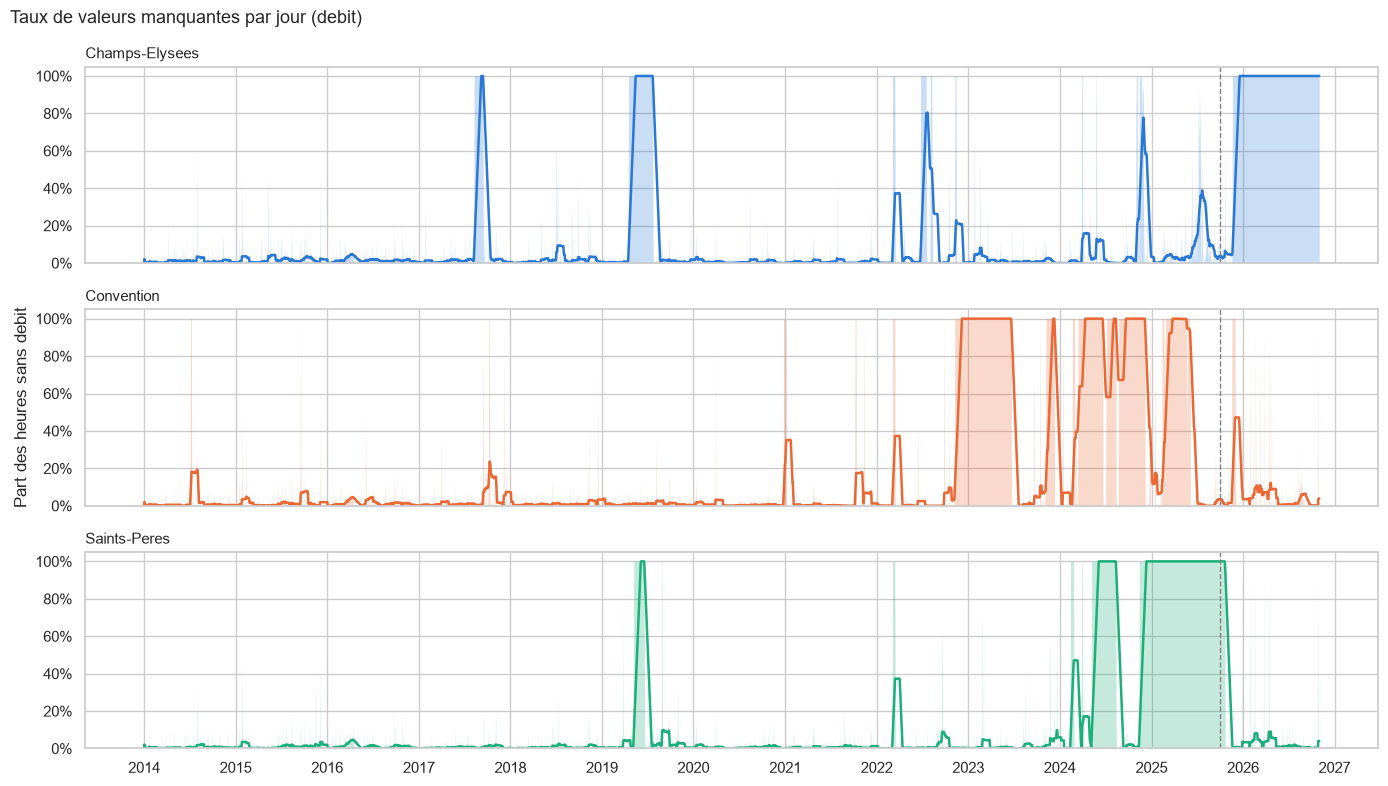

In [6]:
VARIABLE = "debit"

na_jour = (
    df.assign(na=df[VARIABLE].isna())
    .groupby(["axe", df["datetime"].dt.date])["na"].mean()
    .unstack("axe")
)
na_jour.index = pd.to_datetime(na_jour.index)
debut_recent = df.loc[df["source"] == "recent", "datetime"].min().tz_localize(None)

fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True, sharey=True)
for ax, axe in zip(axes, AXES):
    ax.fill_between(na_jour.index, na_jour[axe], color=COULEURS[axe], alpha=0.25, linewidth=0)
    ax.plot(na_jour.index, na_jour[axe].rolling(30, min_periods=1).mean(), color=COULEURS[axe], linewidth=1.8)
    ax.axvline(debut_recent, color="grey", linestyle="--", linewidth=1)
    ax.set_title(axe, loc="left", fontsize=11)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1))
    ax.set_ylim(0, 1.05)
axes[1].set_ylabel(f"Part des heures sans {VARIABLE}")
axes[-1].xaxis.set_major_locator(plt.matplotlib.dates.YearLocator())
axes[-1].xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%Y"))
fig.suptitle(f"Taux de valeurs manquantes par jour ({VARIABLE})", x=0.01, ha="left", fontsize=13)
plt.tight_layout()
plt.show()

## Feature Engineering